# Métodos de la revisión de literatura

Explicaciones de los métodos que aparecen en los artículos de mi revisión de literatura. Los métodos están organizados **por función**: cada función es una sección de nivel 1 y cada método es una subsección dentro de ella.

Cada método sigue siempre el mismo orden:

1. **Concepto** – qué es y para qué sirve, en palabras simples.
2. **Descripción del procedimiento** – paso a paso.
3. **Fórmulas** – en LaTeX, con el significado de cada símbolo y una descripción en palabras.
4. **Código** – en Python, con datos de ejemplo.
5. **Gráficas** – que muestran visualmente cómo funciona el método.
6. **Fortalezas y debilidades** – ventajas, desventajas y limitaciones.
7. **Uso en la literatura** – en qué artículos de la revisión aparece.

El texto está en español; el código, en inglés.

## Tabla de contenido

| Función | Método |
|---|---|
| [1. Descomposición de señales](#descomposicion-de-senales) | [1.1 EMD (Empirical Mode Decomposition)](#emd) |
| [2. Envolvente de amplitud / amplitud instantánea](#envolvente-de-amplitud) | [2.1 Transformada de Hilbert](#transformada-de-hilbert) |

### Configuración

Librerías y estilo de gráficas que usan todos los métodos (ver `requirements.txt`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.signal import argrelextrema, hilbert
from PyEMD import EMD

# Shared plot style: thin lines, recessive grid, no top/right spines
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.color": "#e3e2de",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#2b2b2a",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 1.4,
    "legend.frameon": False,
})

# Fixed color roles (same meaning in every plot)
COLOR_SIGNAL = "#8a8984"   # raw / measured signal (neutral gray)
COLOR_1 = "#2a78d6"        # first component / mode 1 (blue)
COLOR_2 = "#eb6834"        # second component / mode 2 (orange)
COLOR_3 = "#1baf7a"        # third series: reference / mean (aqua)
COLOR_TRUE = "#0b0b0b"     # exact (true) reference curve, dashed

rng = np.random.default_rng(seed=42)  # reproducible example noise

<a id="descomposicion-de-senales"></a>
# 1. Descomposición de señales

Métodos que separan una señal en componentes más simples (por ejemplo, una componente por cada frecuencia dominante), para poder analizar cada una por separado.

<a id="emd"></a>
## 1.1 EMD (Empirical Mode Decomposition)

### Concepto

La **descomposición empírica en modos** (EMD, Huang et al., 1998) separa una señal en un conjunto de componentes llamadas **IMF** (*Intrinsic Mode Functions*, funciones de modo intrínseco). Cada IMF oscila alrededor de cero y tiene aproximadamente **una sola frecuencia dominante**. La primera IMF contiene las oscilaciones más rápidas y las siguientes son cada vez más lentas; lo que sobra al final es un **residuo** (la tendencia).

Si se suman todas las IMF y el residuo, se recupera exactamente la señal original.

Se llama **"empírica"** porque no supone funciones base fijas (como los senos y cosenos de la transformada de Fourier, o las *wavelets*): las componentes salen de la propia señal, a partir de sus máximos y mínimos locales. Por eso se adapta bien a señales **no estacionarias** (cuyas propiedades cambian en el tiempo) y **no lineales**.

Para qué sirve: aislar cada componente de frecuencia de una señal medida (por ejemplo, la respuesta de un vehículo que cruza un puente, que mezcla varios modos de vibración y ruido) para después analizarla sola, por ejemplo con la transformada de Hilbert (sección 2.1).

Una función es IMF si cumple dos condiciones:

1. El número de extremos (máximos + mínimos) y el número de cruces por cero son iguales o difieren como máximo en uno.
2. En todo instante, el promedio de la envolvente superior (que une los máximos) y la inferior (que une los mínimos) es cero, es decir, la función oscila de forma pareja alrededor de cero.

### Descripción del procedimiento

El proceso para extraer cada IMF se llama **cribado** (*sifting*):

1. **Envolventes.** Se ubican todos los máximos locales de la señal y se unen con una curva suave (un **spline cúbico**): esa es la envolvente superior $e_{max}(t)$. Se hace lo mismo con los mínimos locales para obtener la envolvente inferior $e_{min}(t)$.
2. **Media y resta.** Se calcula la media de las dos envolventes, $m(t)$, y se resta a la señal: $h(t) = x(t) - m(t)$.
3. **Repetir.** Se repiten los pasos 1 y 2 sobre $h(t)$ (tomando $h$ como la nueva señal) hasta que el resultado oscile de forma pareja alrededor de cero, es decir, hasta que cumpla las condiciones de IMF (en la práctica se usa un criterio de parada, por ejemplo, que $h$ casi no cambie entre dos iteraciones). Ese resultado es la **primera IMF**, $c_1(t)$, la de frecuencia más alta.
4. **Siguientes IMF.** Se resta la IMF de la señal, $r_1(t) = x(t) - c_1(t)$, y se repite todo el proceso sobre $r_1(t)$ para obtener $c_2(t)$, luego $c_3(t)$, etc., cada una de menor frecuencia.
5. **Fin.** El proceso termina cuando lo que queda, $r_n(t)$, ya no tiene oscilaciones (es monótono o tiene a lo sumo un extremo): ese es el **residuo**.

### Fórmulas

**Media de las envolventes**

$$
m(t) = \frac{e_{max}(t) + e_{min}(t)}{2}
$$

Donde:

- $m(t)$: media local de la señal en el instante $t$ (la "línea central" alrededor de la cual oscila).
- $e_{max}(t)$: envolvente superior, spline cúbico que pasa por todos los máximos locales.
- $e_{min}(t)$: envolvente inferior, spline cúbico que pasa por todos los mínimos locales.
- $t$: tiempo.

En palabras: en cada instante se toma el punto medio entre la envolvente de arriba y la de abajo. Si la señal oscilara perfectamente alrededor de cero, esta media sería cero en todo momento.

**Paso de cribado**

$$
h(t) = x(t) - m(t)
$$

Donde:

- $h(t)$: señal candidata a IMF después de un paso de cribado.
- $x(t)$: señal sobre la que se está cribando (la original en la primera iteración, o el $h$ anterior en las siguientes).
- $m(t)$: media de las envolventes (fórmula anterior).

En palabras: a la señal se le quita su línea central local, de modo que lo que queda oscila más cerca de cero. Repitiendo esto varias veces se obtiene una IMF.

**Reconstrucción de la señal**

$$
x(t) = \sum_{i=1}^{n} c_i(t) + r_n(t)
$$

Donde:

- $x(t)$: señal original.
- $c_i(t)$: IMF número $i$ ($i = 1$ es la de mayor frecuencia, $i = n$ la de menor).
- $n$: número total de IMF extraídas.
- $r_n(t)$: residuo final (tendencia que queda después de extraer las $n$ IMF).

En palabras: la señal original es exactamente la suma de todas sus IMF más el residuo. La EMD no pierde información, solo la reparte en componentes.

### Código

**Señal de ejemplo:** dos componentes senoidales de 5.65 Hz y 22.62 Hz (frecuencias del ejemplo de la sección 2.1) más ruido blanco gaussiano. Se usa la clase `EMD` de la librería PyEMD (paquete `EMD-signal`).

In [2]:
# --- Example signal: two sinusoids + white noise ---
fs = 500.0                       # sampling frequency (Hz)
duration = 2.0                   # signal length (s)
t = np.arange(0, duration, 1 / fs)

f_low, f_high = 5.65, 22.62      # component frequencies (Hz)
component_low = 1.0 * np.sin(2 * np.pi * f_low * t)
component_high = 0.5 * np.sin(2 * np.pi * f_high * t)
noise = 0.15 * rng.standard_normal(t.size)

signal = component_low + component_high + noise

# --- Run EMD ---
emd = EMD()
emd.emd(signal, t)
imfs, residue = emd.get_imfs_and_residue()
print(f"Number of IMFs: {imfs.shape[0]}")


def dominant_frequency(x, fs):
    # Frequency of the largest FFT peak (ignoring the DC term)
    spectrum = np.abs(np.fft.rfft(x - x.mean()))
    freqs = np.fft.rfftfreq(x.size, 1 / fs)
    return freqs[np.argmax(spectrum[1:]) + 1]


for i, imf in enumerate(imfs, start=1):
    print(f"IMF {i}: dominant frequency = {dominant_frequency(imf, fs):6.2f} Hz, "
          f"RMS = {np.sqrt(np.mean(imf**2)):.3f}")

# --- Check the reconstruction x(t) = sum(c_i) + r_n ---
reconstruction = imfs.sum(axis=0) + residue
print(f"Max reconstruction error: {np.max(np.abs(signal - reconstruction)):.2e}")

Number of IMFs: 6
IMF 1: dominant frequency = 157.00 Hz, RMS = 0.116
IMF 2: dominant frequency =  22.50 Hz, RMS = 0.093
IMF 3: dominant frequency =  22.50 Hz, RMS = 0.350
IMF 4: dominant frequency =   5.50 Hz, RMS = 0.708
IMF 5: dominant frequency =   2.00 Hz, RMS = 0.028
IMF 6: dominant frequency =   1.00 Hz, RMS = 0.007
Max reconstruction error: 1.73e-18


Para ver el cribado "por dentro", la siguiente función implementa **un paso de cribado** a mano (pasos 1 y 2 del procedimiento) con `scipy`, sin usar PyEMD.

In [3]:
def sifting_step(x, t):
    # Local maxima and minima (indices)
    idx_max = argrelextrema(x, np.greater)[0]
    idx_min = argrelextrema(x, np.less)[0]

    # Cubic-spline envelopes through the extrema
    upper_envelope = CubicSpline(t[idx_max], x[idx_max])(t)
    lower_envelope = CubicSpline(t[idx_min], x[idx_min])(t)

    # Mean envelope m(t) and candidate IMF h(t) = x(t) - m(t)
    mean_envelope = (upper_envelope + lower_envelope) / 2
    h = x - mean_envelope
    return idx_max, idx_min, upper_envelope, lower_envelope, mean_envelope, h


# Noise-free version of the signal, so the extrema are easy to see
clean_signal = component_low + component_high
idx_max, idx_min, upper_env, lower_env, mean_env, h1 = sifting_step(clean_signal, t)

### Gráficas

**(a) Un paso de cribado.** La señal (sin ruido, para que se vean los extremos), sus máximos y mínimos, las envolventes de spline cúbico y la media $m(t)$. Abajo, $h(t) = x(t) - m(t)$ comparado con la componente rápida real: después de un solo paso ya se parece mucho a la componente de 22.62 Hz, porque $m(t)$ capturó casi toda la componente lenta.

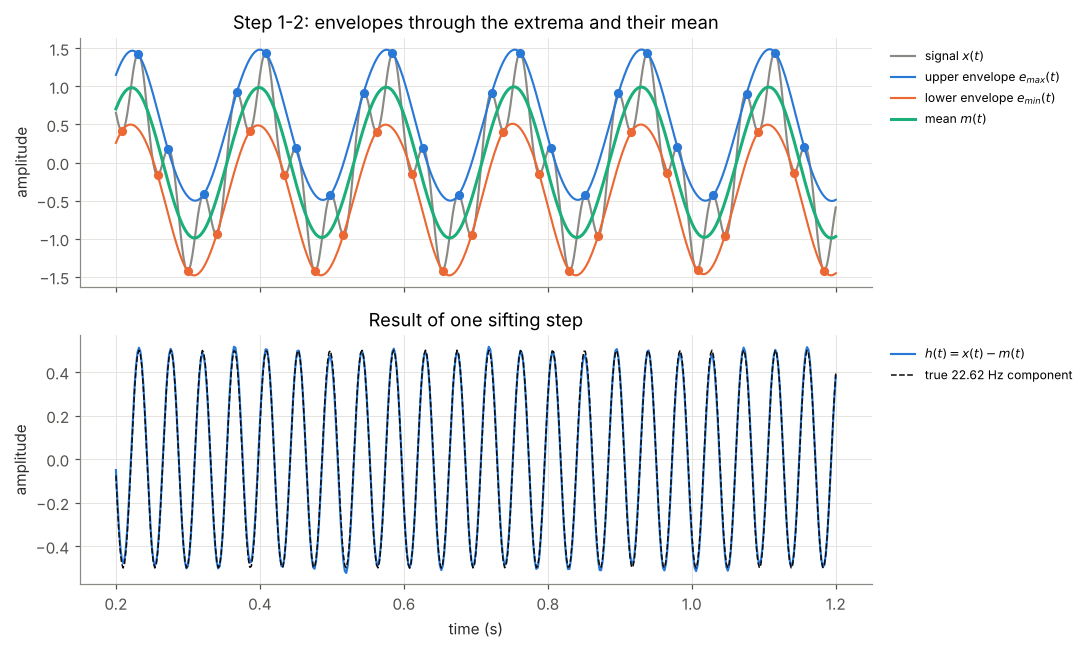

In [4]:
window = (t >= 0.2) & (t <= 1.2)   # zoom into 1 s, away from the edges

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax = axes[0]
ax.plot(t[window], clean_signal[window], color=COLOR_SIGNAL, label="signal $x(t)$")
ax.plot(t[window], upper_env[window], color=COLOR_1, label="upper envelope $e_{max}(t)$")
ax.plot(t[window], lower_env[window], color=COLOR_2, label="lower envelope $e_{min}(t)$")
ax.plot(t[window], mean_env[window], color=COLOR_3, linewidth=2, label="mean $m(t)$")
in_window = lambda idx: idx[(t[idx] >= 0.2) & (t[idx] <= 1.2)]
ax.plot(t[in_window(idx_max)], clean_signal[in_window(idx_max)], "o", ms=5, color=COLOR_1)
ax.plot(t[in_window(idx_min)], clean_signal[in_window(idx_min)], "o", ms=5, color=COLOR_2)
ax.set_ylabel("amplitude")
ax.set_title("Step 1-2: envelopes through the extrema and their mean")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)

ax = axes[1]
ax.plot(t[window], h1[window], color=COLOR_1, label="$h(t) = x(t) - m(t)$")
ax.plot(t[window], component_high[window], "--", color=COLOR_TRUE, linewidth=1,
        label="true 22.62 Hz component")
ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude")
ax.set_title("Result of one sifting step")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)

fig.tight_layout()
plt.show()

**(b) Señal y sus IMF.** Arriba la señal con ruido; debajo cada IMF y el residuo. La primera IMF recoge sobre todo el ruido (frecuencias más altas); luego aparecen las componentes de 22.62 Hz y de 5.65 Hz (por el ruido, parte de la componente de 22.62 Hz puede repartirse en dos IMF vecinas, una forma de mezcla de modos), y al final IMF de baja frecuencia con muy poca energía (en parte, efectos de borde y restos de ruido).

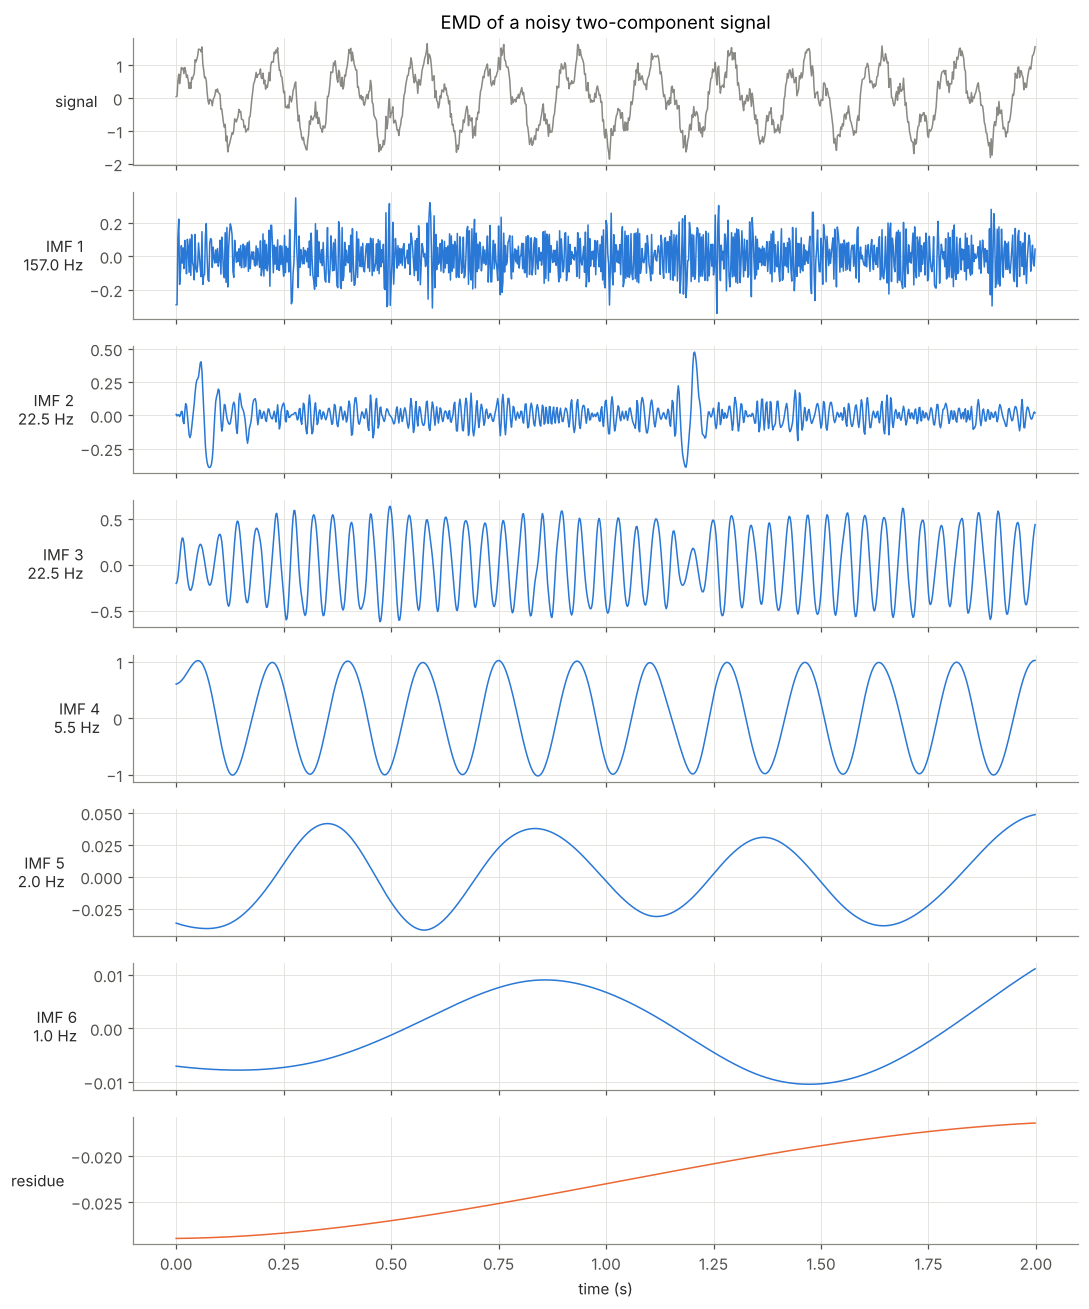

In [5]:
n_imfs = imfs.shape[0]
fig, axes = plt.subplots(n_imfs + 2, 1, figsize=(10, 1.5 * (n_imfs + 2)), sharex=True)

axes[0].plot(t, signal, color=COLOR_SIGNAL, linewidth=1)
axes[0].set_ylabel("signal", rotation=0, ha="right", va="center")

for i, imf in enumerate(imfs):
    f_dom = dominant_frequency(imf, fs)
    axes[i + 1].plot(t, imf, color=COLOR_1, linewidth=1)
    axes[i + 1].set_ylabel(f"IMF {i + 1}\n{f_dom:.1f} Hz", rotation=0, ha="right", va="center")

axes[-1].plot(t, residue, color=COLOR_2, linewidth=1)
axes[-1].set_ylabel("residue", rotation=0, ha="right", va="center")
axes[-1].set_xlabel("time (s)")
axes[0].set_title("EMD of a noisy two-component signal")

fig.tight_layout()
plt.show()

**(c) IMF frente a las componentes reales.** Para cada componente se elige automáticamente, entre las IMF con frecuencia dominante cercana, la de mayor energía, y se compara con la componente verdadera. La coincidencia es buena en el centro y empeora cerca de los bordes (**efecto de borde**: el spline no tiene extremos fuera de la señal para apoyarse).

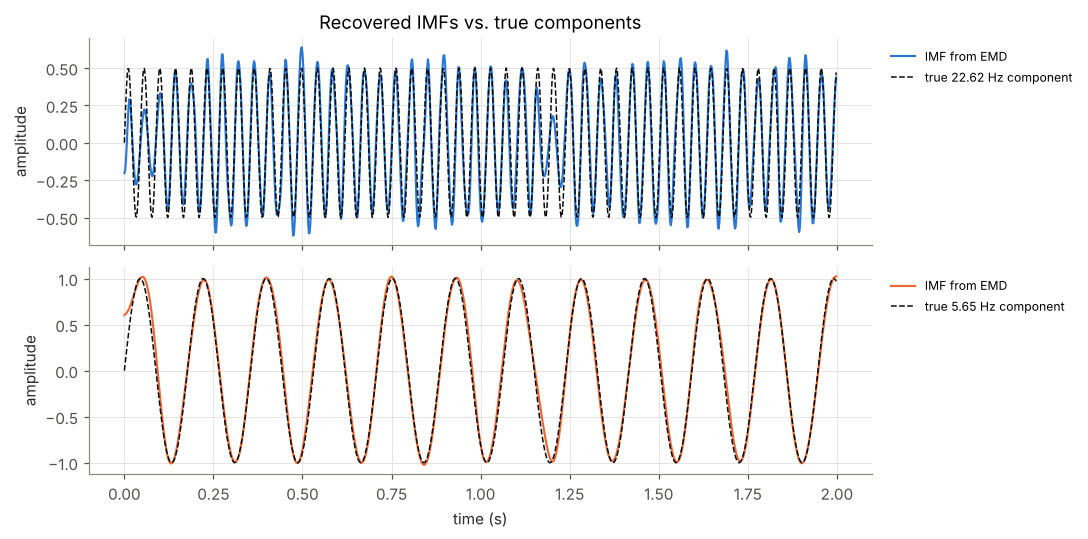

In [6]:
def pick_imf(imfs, fs, target_freq, tolerance=2.0):
    # Among the IMFs whose dominant frequency is within tolerance of the
    # target, return the one with the largest energy (RMS)
    freqs = np.array([dominant_frequency(imf, fs) for imf in imfs])
    rms = np.sqrt(np.mean(imfs**2, axis=1))
    candidates = np.where(np.abs(freqs - target_freq) <= tolerance)[0]
    return imfs[candidates[np.argmax(rms[candidates])]]


imf_high = pick_imf(imfs, fs, f_high)
imf_low = pick_imf(imfs, fs, f_low)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for ax, imf, true, color, f in [
    (axes[0], imf_high, component_high, COLOR_1, f_high),
    (axes[1], imf_low, component_low, COLOR_2, f_low),
]:
    ax.plot(t, imf, color=color, label="IMF from EMD")
    ax.plot(t, true, "--", color=COLOR_TRUE, linewidth=1, label=f"true {f} Hz component")
    ax.set_ylabel("amplitude")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
axes[0].set_title("Recovered IMFs vs. true components")
axes[1].set_xlabel("time (s)")
fig.tight_layout()
plt.show()

**(d) Debilidad: mezcla de modos.** Si las dos frecuencias están muy cerca (aquí 5.65 Hz y 7.0 Hz, relación menor que 2), la EMD no puede separarlas: las dos quedan en la **misma IMF**, que aparece como una oscilación con "pulsos" (batido).

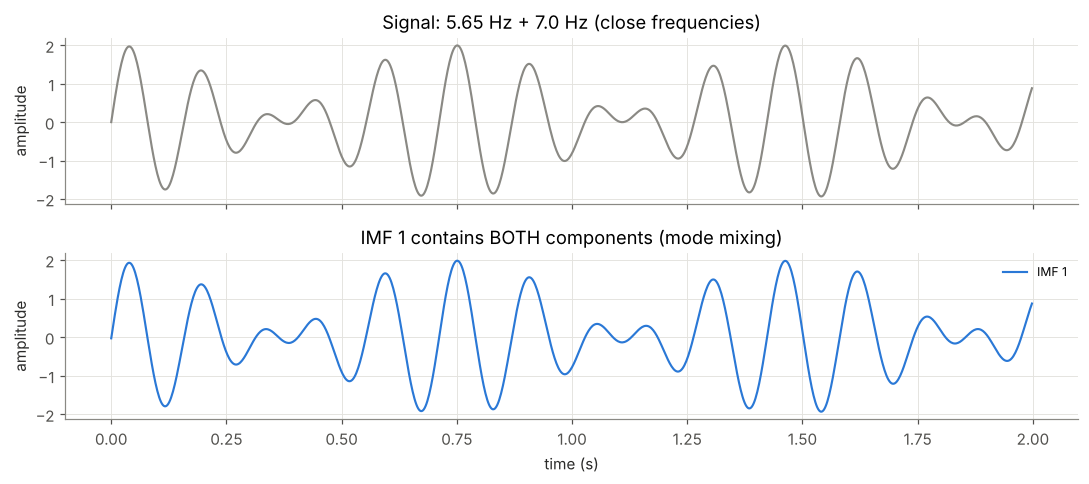

Number of IMFs: 4; RMS share of IMF 1: 100%


In [7]:
f_close = 7.0                                   # close to f_low = 5.65 Hz
close_signal = np.sin(2 * np.pi * f_low * t) + np.sin(2 * np.pi * f_close * t)

emd_close = EMD()
emd_close.emd(close_signal, t)
imfs_close, _ = emd_close.get_imfs_and_residue()

fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
axes[0].plot(t, close_signal, color=COLOR_SIGNAL)
axes[0].set_title(f"Signal: {f_low} Hz + {f_close} Hz (close frequencies)")
axes[0].set_ylabel("amplitude")
axes[1].plot(t, imfs_close[0], color=COLOR_1, label="IMF 1")
axes[1].set_title("IMF 1 contains BOTH components (mode mixing)")
axes[1].set_xlabel("time (s)")
axes[1].set_ylabel("amplitude")
axes[1].legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

print(f"Number of IMFs: {imfs_close.shape[0]}; "
      f"RMS share of IMF 1: {np.sqrt(np.mean(imfs_close[0]**2)) / np.sqrt(np.mean(close_signal**2)):.0%}")

### Fortalezas y debilidades

**Fortalezas**

- **Adaptativa:** las componentes se obtienen de la propia señal; no hay que elegir una base (senos, *wavelet* madre, etc.).
- **Apta para señales no estacionarias y no lineales**, donde Fourier supone, en cambio, que la señal es estacionaria y la representa con senos de amplitud constante.
- **Reconstrucción exacta:** la suma de IMF + residuo devuelve la señal original.
- Cada IMF es una señal de una sola componente, ideal para aplicar después la **transformada de Hilbert** (EMD + Hilbert = transformada de Hilbert-Huang, HHT).

**Debilidades y limitaciones**

- **Mezcla de modos (*mode mixing*):** dos frecuencias cercanas (relación de frecuencias menor que ~2) pueden quedar en la misma IMF, como en la gráfica (d); también una misma componente puede repartirse entre varias IMF cuando hay ruido o intermitencias.
- **Efectos de borde:** cerca de los extremos de la señal no hay máximos/mínimos para apoyar los splines, y las envolventes se desvían; el error se propaga hacia adentro.
- **Sensibilidad al ruido:** el ruido agrega extremos falsos, genera IMF adicionales y puede cambiar qué componente cae en cada IMF.
- **Sin fundamento matemático cerrado:** se define como un algoritmo, no con una fórmula analítica; el resultado depende del criterio de parada del cribado y del tipo de interpolación, y es difícil de analizar teóricamente.
- **Variantes que lo mitigan:**
  - **EEMD** (*Ensemble EMD*, Wu y Huang, 2009): agrega muchas realizaciones de ruido blanco a la señal, aplica EMD a cada una y promedia las IMF; el ruido añadido ayuda a separar las escalas y reduce la mezcla de modos.
  - **CEEMDAN** (*Complete EEMD with Adaptive Noise*, Torres et al., 2011): versión mejorada de la EEMD en la que la reconstrucción es exacta y se necesitan menos realizaciones.
  - Ambas están disponibles en PyEMD (`EEMD`, `CEEMDAN`).

### Uso en la literatura

- **Origen del método:** Huang, N. E., Shen, Z., Long, S. R., Wu, M. C., Shih, H. H., Zheng, Q., Yen, N.-C., Tung, C. C. y Liu, H. H. (1998). The empirical mode decomposition and the Hilbert spectrum for nonlinear and non-stationary time series analysis. *Proceedings of the Royal Society of London A*, 454, 903–995.
- **Artículos de mi revisión:** *(por completar a medida que aparezca en los artículos revisados)*. En la literatura de monitoreo indirecto de puentes con vehículos, la EMD se usa típicamente para separar la componente de cada modo del puente en la respuesta del vehículo antes de aplicar la transformada de Hilbert (sección 2.1).

<a id="envolvente-de-amplitud"></a>
# 2. Envolvente de amplitud / amplitud instantánea

Métodos que calculan, en cada instante, la amplitud "real" de una oscilación (su envolvente), sin las subidas y bajadas propias de cada ciclo; a menudo también entregan la fase y la frecuencia instantáneas.

<a id="transformada-de-hilbert"></a>
## 2.1 Transformada de Hilbert

### Concepto

La **transformada de Hilbert** genera, a partir de una señal $x(t)$, una copia de la misma señal **desfasada 90°** (un coseno se convierte en seno, un seno en menos coseno). Combinando la señal original con esa copia se forma la **señal analítica**, un número complejo en cada instante cuyo módulo es la **amplitud instantánea** (la envolvente) y cuyo ángulo es la **fase instantánea**; la derivada de la fase da la **frecuencia instantánea**.

**Por qué funciona:** donde una de las dos señales pasa por cero, la otra está en su máximo (por el desfase de 90°). Así, al combinarlas como $\sqrt{x^2 + \mathcal{H}[x]^2}$ (igual que $\sqrt{\cos^2 + \sin^2} = 1$), las subidas y bajadas del ciclo se cancelan y queda la amplitud real en cada instante.

**Condición para que tenga sentido físico:** la señal no tiene que ser una senoidal pura, pero debe tener **una sola frecuencia dominante** (señal *monocomponente*) y una **amplitud que cambie lentamente** respecto a la oscilación. Si la señal mezcla varias frecuencias, la envolvente sale ondulada y pierde significado físico. Por eso, en la práctica, **primero se aplica EMD** (sección 1.1) para separar la señal en IMF y luego se aplica Hilbert a cada IMF. Esa combinación, EMD + Hilbert, es la **transformada de Hilbert-Huang (HHT)**.

Para qué sirve (ejemplo de la revisión): cuando un vehículo cruza un puente, la respuesta asociada a un modo del puente es una oscilación a la frecuencia de ese modo cuya amplitud sigue la **forma modal** en la posición del vehículo. La envolvente de Hilbert recupera esa amplitud y, por lo tanto, la forma modal (Malekjafarian y OBrien, 2017).

### Descripción del procedimiento

1. **Preparar la señal:** asegurarse de que es monocomponente (filtrándola alrededor de la frecuencia de interés o extrayendo una IMF con EMD) y quitarle la media.
2. **Calcular la transformada de Hilbert** $\mathcal{H}[x(t)]$, la copia desfasada 90°. En la práctica se calcula con la FFT: se anulan las frecuencias negativas del espectro y se duplican las positivas; la inversa da directamente la señal analítica (`scipy.signal.hilbert` hace esto y devuelve $z(t)$).
3. **Formar la señal analítica** $z(t) = x(t) + j\,\mathcal{H}[x(t)]$.
4. **Amplitud instantánea (envolvente):** el módulo $A(t) = |z(t)|$.
5. **Fase instantánea:** el ángulo $\theta(t)$ de $z(t)$, "desenrollada" (*unwrapped*) para quitar los saltos de $2\pi$.
6. **Frecuencia instantánea:** la derivada de la fase dividida entre $2\pi$.
7. **Descartar los bordes:** los primeros y últimos ciclos tienen efectos de borde y no deben interpretarse.

### Fórmulas

**Transformada de Hilbert**

$$
\mathcal{H}[x(t)] = \frac{1}{\pi}\,\text{p.v.}\int_{-\infty}^{\infty} \frac{x(\tau)}{t-\tau}\,d\tau
$$

Donde:

- $\mathcal{H}[x(t)]$: transformada de Hilbert de $x$, es decir, la señal desfasada 90°.
- $x(\tau)$: señal original evaluada en el instante de integración $\tau$.
- $t$: instante en el que se calcula la transformada.
- $\tau$: variable de integración (recorre todos los instantes de la señal).
- $\frac{1}{t-\tau}$: núcleo de la transformada; da más peso a los instantes cercanos a $t$ y cambia de signo antes y después de $t$.
- $\text{p.v.}$: **valor principal de Cauchy**. El integrando se vuelve infinito en $\tau = t$; el valor principal significa que se excluye un intervalo simétrico $(t-\varepsilon,\ t+\varepsilon)$ alrededor de ese punto y se toma el límite cuando $\varepsilon \to 0$, de modo que los dos infinitos (de signo contrario) se cancelan.

En palabras: la transformada de Hilbert es la convolución de la señal con $\frac{1}{\pi t}$. Su efecto es retrasar 90° la fase de cada componente de frecuencia sin cambiar su amplitud: $\mathcal{H}[\cos(\omega t)] = \sin(\omega t)$ y $\mathcal{H}[\sin(\omega t)] = -\cos(\omega t)$.

**Señal analítica**

$$
z(t) = x(t) + j\,\mathcal{H}[x(t)]
$$

Donde:

- $z(t)$: señal analítica (compleja).
- $x(t)$: señal original (parte real).
- $\mathcal{H}[x(t)]$: transformada de Hilbert (parte imaginaria).
- $j$: unidad imaginaria, $j = \sqrt{-1}$.

En palabras: se pone la señal original como parte real y su copia desfasada 90° como parte imaginaria. Para un coseno, $z(t) = \cos(\omega t) + j\sin(\omega t) = e^{j\omega t}$: un vector que gira en el plano complejo con longitud igual a la amplitud.

**Amplitud instantánea (envolvente)**

$$
A(t) = \sqrt{x(t)^2 + \mathcal{H}[x(t)]^2}
$$

Donde:

- $A(t)$: amplitud instantánea o envolvente en el instante $t$ (es el módulo $|z(t)|$).
- $x(t)$: señal original.
- $\mathcal{H}[x(t)]$: transformada de Hilbert de la señal.

En palabras: es la longitud del vector $z(t)$. Como una de las dos señales está en su máximo cuando la otra pasa por cero, la suma de cuadrados no "sube y baja" con el ciclo y da la amplitud real en cada instante. Siempre es positiva, así que **no conserva el signo** de la señal.

**Fase instantánea**

$$
\theta(t) = \arctan\frac{\mathcal{H}[x(t)]}{x(t)}
$$

Donde:

- $\theta(t)$: fase instantánea (rad), el ángulo del vector $z(t)$.
- $\mathcal{H}[x(t)]$: transformada de Hilbert (parte imaginaria de $z$).
- $x(t)$: señal original (parte real de $z$).

En palabras: indica en qué punto del ciclo está la oscilación en cada instante. En el código se usa el arcotangente de cuatro cuadrantes (`np.angle`, equivalente a `atan2`) para obtener el ángulo correcto en los cuatro cuadrantes, y luego `np.unwrap` para que la fase crezca de forma continua en lugar de saltar de $\pi$ a $-\pi$.

**Frecuencia instantánea**

$$
f(t) = \frac{1}{2\pi}\frac{d\theta}{dt}
$$

Donde:

- $f(t)$: frecuencia instantánea (Hz).
- $\frac{d\theta}{dt}$: velocidad con la que cambia la fase (rad/s), es decir, la frecuencia angular instantánea $\omega(t)$.
- $2\pi$: factor para pasar de rad/s a ciclos por segundo (Hz).

En palabras: la frecuencia es qué tan rápido avanza la fase. Si la fase avanza $2\pi$ rad (un ciclo) cada 0.177 s, la frecuencia es 5.65 Hz. En señales discretas, la derivada se aproxima con diferencias finitas (`np.gradient`).

### Código

**Aplicación de Malekjafarian y OBrien (2017):** un vehículo cruza un puente simplemente apoyado de $L = 15$ m a velocidad constante $v = 2$ m/s. La componente de la respuesta asociada a un modo del puente es su **forma modal**, evaluada en la posición del vehículo $vt$, multiplicada por una oscilación a la frecuencia del modo:

$$
x(t) = \phi(vt)\cos(2\pi f t)
$$

- **Modo 1:** $\phi_1(x) = \sin(\pi x / L)$, $f_1 = 5.65$ Hz.
- **Modo 2:** $\phi_2(x) = \sin(2\pi x / L)$, $f_2 = 22.62$ Hz.

(En una viga simplemente apoyada $f_n \propto n^2$, por eso $f_2 \approx 4 f_1$.) La envolvente de Hilbert de cada señal debería reproducir la forma modal: $A(t) \approx |\phi(vt)|$.

In [8]:
# --- Bridge and vehicle (Malekjafarian & OBrien, 2017) ---
bridge_length = 15.0             # simply supported span L (m)
vehicle_speed = 2.0              # vehicle speed v (m/s)
fs_bridge = 1000.0               # sampling frequency (Hz)

crossing_time = bridge_length / vehicle_speed           # 7.5 s
t_cross = np.arange(0, crossing_time, 1 / fs_bridge)
position = vehicle_speed * t_cross                      # vehicle position x = v t (m)

# Mode shapes and frequencies
phi_1 = np.sin(np.pi * position / bridge_length)        # mode 1
phi_2 = np.sin(2 * np.pi * position / bridge_length)    # mode 2
f_1, f_2 = 5.65, 22.62                                  # natural frequencies (Hz)

# Measured components: mode shape x oscillation at the mode frequency
x_1 = phi_1 * np.cos(2 * np.pi * f_1 * t_cross)
x_2 = phi_2 * np.cos(2 * np.pi * f_2 * t_cross)


def hilbert_analysis(x, fs):
    # Analytic signal z(t) = x(t) + j H[x(t)]
    z = hilbert(x)
    hilbert_x = np.imag(z)                               # H[x(t)]
    amplitude = np.abs(z)                                # A(t)
    phase = np.unwrap(np.angle(z))                       # theta(t)
    inst_freq = np.gradient(phase, 1 / fs) / (2 * np.pi) # f(t)
    return hilbert_x, amplitude, phase, inst_freq


hilbert_1, envelope_1, phase_1, freq_1 = hilbert_analysis(x_1, fs_bridge)
hilbert_2, envelope_2, phase_2, freq_2 = hilbert_analysis(x_2, fs_bridge)

# Accuracy away from the edges (central 80 % of the span)
interior = (position > 0.1 * bridge_length) & (position < 0.9 * bridge_length)
print(f"Mode 1: max |A - |phi||  = {np.max(np.abs(envelope_1 - np.abs(phi_1))[interior]):.3f}, "
      f"median f(t) = {np.median(freq_1[interior]):.2f} Hz")
print(f"Mode 2: max |A - |phi||  = {np.max(np.abs(envelope_2 - np.abs(phi_2))[interior]):.3f}, "
      f"median f(t) = {np.median(freq_2[interior]):.2f} Hz")

Mode 1: max |A - |phi||  = 0.000, median f(t) = 5.65 Hz
Mode 2: max |A - |phi||  = 0.000, median f(t) = 22.62 Hz


### Gráficas

**(1) Señal y su transformada de Hilbert (desfase de 90°).** Tramo de 1 s alrededor del centro del puente. Los puntos marcan los cruces por cero de la señal: justo ahí la transformada de Hilbert está en un máximo o un mínimo, y viceversa. Por eso la envolvente $A(t)$ queda por encima de ambas sin oscilar.

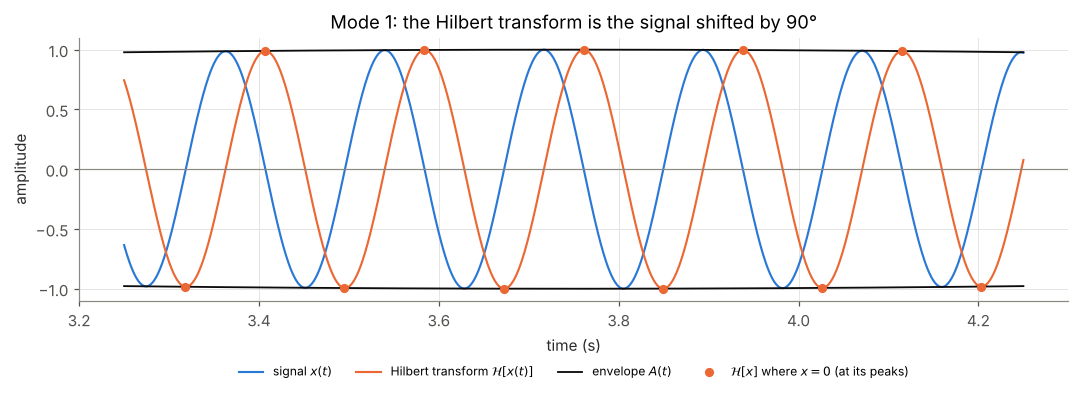

In [9]:
segment = (t_cross >= 3.25) & (t_cross <= 4.25)          # ~1 s around midspan
ts, xs, hs, es = t_cross[segment], x_1[segment], hilbert_1[segment], envelope_1[segment]

# Zero crossings of x(t) (sign changes)
zero_idx = np.where(np.diff(np.sign(xs)) != 0)[0]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(ts, xs, color=COLOR_1, label="signal $x(t)$")
ax.plot(ts, hs, color=COLOR_2, label=r"Hilbert transform $\mathcal{H}[x(t)]$")
ax.plot(ts, es, color=COLOR_TRUE, linewidth=1.2, label="envelope $A(t)$")
ax.plot(ts, -es, color=COLOR_TRUE, linewidth=1.2)
ax.plot(ts[zero_idx], hs[zero_idx], "o", ms=5, color=COLOR_2,
        label=r"$\mathcal{H}[x]$ where $x = 0$ (at its peaks)")
ax.axhline(0, color="#8a8984", linewidth=0.8)
ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude")
ax.set_title("Mode 1: the Hilbert transform is the signal shifted by 90°")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=8)
fig.tight_layout()
plt.show()

**(2) Envolvente contra la posición del vehículo, comparada con la forma modal real.** Para el modo 1 la envolvente coincide con $\phi_1$. Para el modo 2 la envolvente coincide con $|\phi_2|$, **no** con $\phi_2$: la amplitud instantánea siempre es positiva, así que **se pierde el signo** de la forma modal (la segunda mitad del modo 2, que es negativa, aparece reflejada). Para recuperar el signo hace falta información adicional (por ejemplo, la fase: en el nodo, a la mitad del vano, la fase salta 180°). En este ejemplo ideal la envolvente coincide también en los extremos porque la señal empieza y termina con amplitud cero; con señales reales (que no empiezan ni terminan en cero, y con ruido) aparecen desviaciones por efecto de borde.

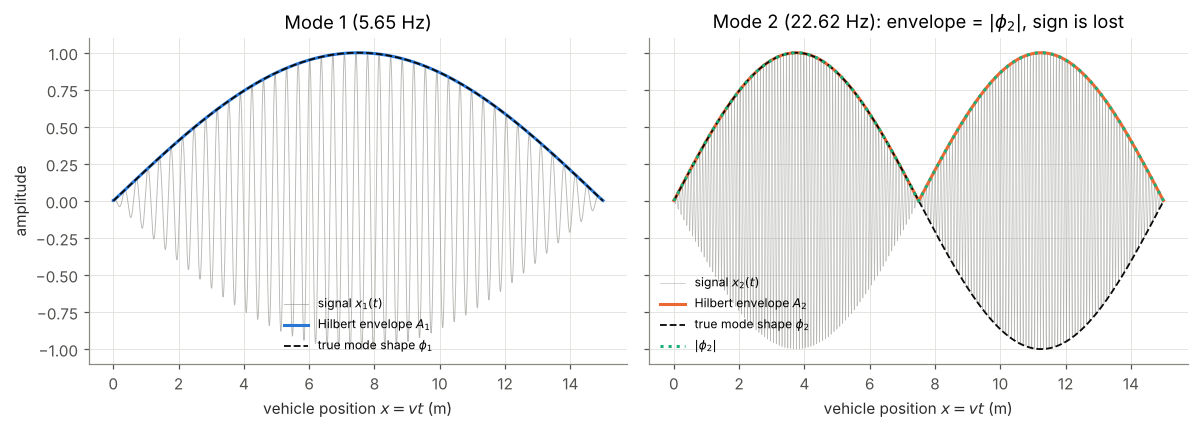

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

ax = axes[0]
ax.plot(position, x_1, color=COLOR_SIGNAL, linewidth=0.6, alpha=0.6, label="signal $x_1(t)$")
ax.plot(position, envelope_1, color=COLOR_1, linewidth=2, label="Hilbert envelope $A_1$")
ax.plot(position, phi_1, "--", color=COLOR_TRUE, linewidth=1.2, label=r"true mode shape $\phi_1$")
ax.set_title(f"Mode 1 ({f_1} Hz)")
ax.set_xlabel("vehicle position $x = vt$ (m)")
ax.set_ylabel("amplitude")
ax.legend(loc="lower center", fontsize=8)

ax = axes[1]
ax.plot(position, x_2, color=COLOR_SIGNAL, linewidth=0.4, alpha=0.6, label="signal $x_2(t)$")
ax.plot(position, envelope_2, color=COLOR_2, linewidth=2, label="Hilbert envelope $A_2$")
ax.plot(position, phi_2, "--", color=COLOR_TRUE, linewidth=1.2, label=r"true mode shape $\phi_2$")
ax.plot(position, np.abs(phi_2), ":", color=COLOR_3, linewidth=2, label=r"$|\phi_2|$")
ax.set_title(f"Mode 2 ({f_2} Hz): envelope = $|\\phi_2|$, sign is lost")
ax.set_xlabel("vehicle position $x = vt$ (m)")
ax.legend(loc="lower left", fontsize=8)

fig.tight_layout()
plt.show()

**(3) Frecuencia instantánea.** En el interior del vano la frecuencia instantánea es constante e igual a la frecuencia del modo (5.65 Hz y 22.62 Hz). Se desvía en los bordes (efecto de borde, donde además la amplitud tiende a cero) y, en el modo 2, en el **nodo** a la mitad del vano: ahí la amplitud es cero, la fase salta 180° y la frecuencia instantánea pierde significado. Regla práctica: la frecuencia instantánea solo es confiable donde la amplitud no es pequeña.

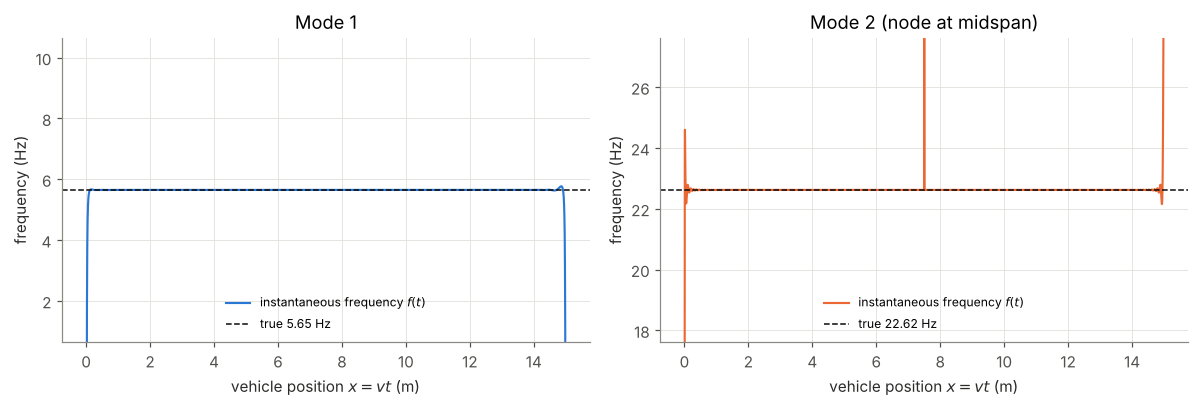

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, freq, f_true, color, title in [
    (axes[0], freq_1, f_1, COLOR_1, "Mode 1"),
    (axes[1], freq_2, f_2, COLOR_2, "Mode 2 (node at midspan)"),
]:
    ax.plot(position, freq, color=color, label="instantaneous frequency $f(t)$")
    ax.axhline(f_true, linestyle="--", color=COLOR_TRUE, linewidth=1, label=f"true {f_true} Hz")
    ax.set_ylim(f_true - 5, f_true + 5)   # zoom: spikes at edges/node go off-scale
    ax.set_title(title)
    ax.set_xlabel("vehicle position $x = vt$ (m)")
    ax.set_ylabel("frequency (Hz)")
    ax.legend(loc="lower center", fontsize=8)
fig.tight_layout()
plt.show()

**(4) Por qué primero EMD: Hilbert sobre una señal con dos modos frente a HHT.** Si la señal medida contiene los dos modos a la vez, $x(t) = x_1(t) + x_2(t)$, la envolvente de Hilbert sale ondulada y no corresponde a ninguna forma modal. Si primero se separa la señal con EMD y luego se aplica Hilbert a cada IMF (**HHT**), se recupera cada forma modal (en valor absoluto). La excepción es la zona del **nodo del modo 2** (mitad del vano): ahí la amplitud del modo 2 se anula, la EMD pierde sus extremos y mezcla los dos modos en ese tramo (mezcla de modos por intermitencia), así que las dos envolventes se distorsionan localmente.

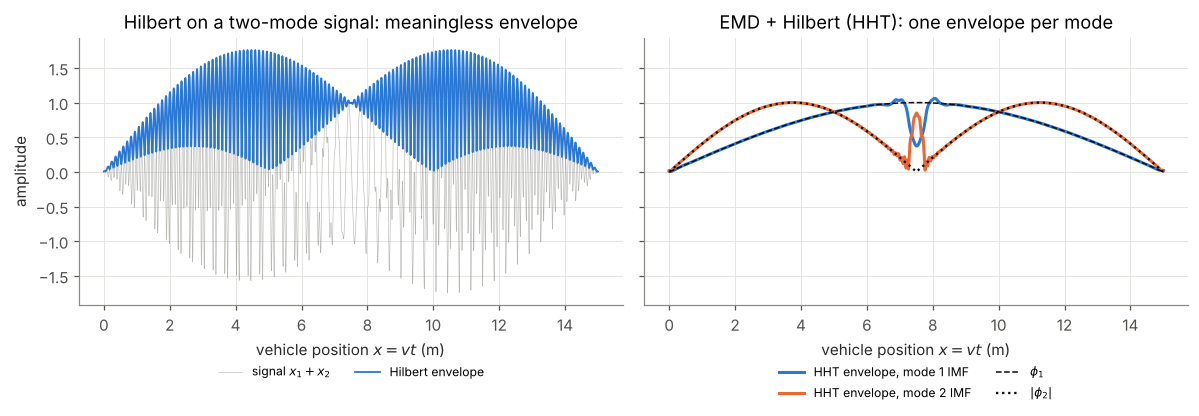

IMF dominant frequencies (Hz): [22.53  5.6   0.13  0.13  0.27]


In [12]:
two_mode_signal = x_1 + x_2

# (a) Hilbert directly on the multi-component signal
_, envelope_mixed, _, _ = hilbert_analysis(two_mode_signal, fs_bridge)

# (b) HHT: EMD first, then Hilbert on each IMF
emd_bridge = EMD(extrema_detection="parabol")
emd_bridge.emd(two_mode_signal, t_cross)
imfs_bridge, _ = emd_bridge.get_imfs_and_residue()
imf_freqs_bridge = np.array([dominant_frequency(imf, fs_bridge) for imf in imfs_bridge])
imf_mode_2 = pick_imf(imfs_bridge, fs_bridge, f_2)
imf_mode_1 = pick_imf(imfs_bridge, fs_bridge, f_1)
_, envelope_hht_1, _, _ = hilbert_analysis(imf_mode_1, fs_bridge)
_, envelope_hht_2, _, _ = hilbert_analysis(imf_mode_2, fs_bridge)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

ax = axes[0]
ax.plot(position, two_mode_signal, color=COLOR_SIGNAL, linewidth=0.4, alpha=0.6,
        label="signal $x_1 + x_2$")
ax.plot(position, envelope_mixed, color=COLOR_1, linewidth=1.2, label="Hilbert envelope")
ax.set_title("Hilbert on a two-mode signal: meaningless envelope")
ax.set_xlabel("vehicle position $x = vt$ (m)")
ax.set_ylabel("amplitude")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8)

ax = axes[1]
ax.plot(position, envelope_hht_1, color=COLOR_1, linewidth=2, label="HHT envelope, mode 1 IMF")
ax.plot(position, envelope_hht_2, color=COLOR_2, linewidth=2, label="HHT envelope, mode 2 IMF")
ax.plot(position, phi_1, "--", color=COLOR_TRUE, linewidth=1, label=r"$\phi_1$")
ax.plot(position, np.abs(phi_2), ":", color=COLOR_TRUE, linewidth=1.5, label=r"$|\phi_2|$")
ax.set_title("EMD + Hilbert (HHT): one envelope per mode")
ax.set_xlabel("vehicle position $x = vt$ (m)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8)

fig.tight_layout()
plt.show()

print("IMF dominant frequencies (Hz):", np.round(imf_freqs_bridge, 2))

### Fortalezas y debilidades

**Fortalezas**

- **Amplitud y frecuencia en cada instante:** a diferencia de la FFT, que da una amplitud promedio por frecuencia para toda la señal, Hilbert entrega $A(t)$ y $f(t)$ punto a punto.
- **Apta para señales no estacionarias**, cuya amplitud o frecuencia cambian en el tiempo (como la respuesta de un vehículo que cruza un puente).
- **Simple y rápida de calcular:** una FFT y una FFT inversa (`scipy.signal.hilbert`); no hay parámetros que ajustar.
- Combinada con EMD (HHT) forma una herramienta completa de análisis tiempo-frecuencia adaptativa.

**Debilidades y limitaciones**

- **Solo tiene sentido con señales de una sola componente** (una frecuencia dominante y amplitud que varía lentamente). Con varias componentes la envolvente y la frecuencia instantánea pierden significado físico, como en la gráfica (4) → hay que filtrar o aplicar EMD antes.
- **Efectos de borde:** como se calcula con la FFT (que supone que la señal es periódica), aparecen errores en el inicio y el final de la señal; se suelen descartar los primeros y últimos ciclos.
- **Sensible al ruido:** el ruido produce fluctuaciones en la envolvente y, sobre todo, picos en la frecuencia instantánea (porque derivar la fase amplifica el ruido); normalmente se filtra o suaviza.
- **Pérdida del signo:** la envolvente es siempre positiva; en formas modales con nodos se obtiene $|\phi|$ y el signo se debe recuperar por otro medio (por ejemplo, la fase).
- **Frecuencia instantánea poco confiable donde la amplitud es casi cero** (nodos, extremos), como se ve en la gráfica (3).

### Uso en la literatura

- **Malekjafarian, A. y OBrien, E. J. (2017).** *On the use of a passing vehicle for the estimation of bridge mode shapes.* Journal of Sound and Vibration, 397, 77–91. La respuesta de un vehículo que cruza el puente se separa en la componente de cada modo del puente y se aplica la transformada de Hilbert para obtener su amplitud instantánea, que reproduce la forma modal (en valor absoluto) en función de la posición del vehículo. El ejemplo de código de esta sección reproduce esa idea con un puente simplemente apoyado de 15 m y un vehículo a 2 m/s.
- **Origen de la HHT (EMD + Hilbert):** Huang et al. (1998), citado en la sección 1.1.